# Problem 1 — Combined Notebook

This notebook combines the HAR data preparation/classical baselines, recurrent models and adding-task experiments, and final model selection/evaluation.

**Run from the `problem1/` directory (or adjust paths as documented).** Restart the kernel and use **Run All** before submission.

> Combined from `problem1_phase2_completed.ipynb`, `problem1.ipynb`, and `problem1_continuation_clean.ipynb`.

---
# A — Data preparation and classical baselines


In [1]:
# Import libraries
# python3.13 -m pip install ipykernel
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

NumPy: 2.5.4
PyTorch: 2.15.0
CUDA available: False


In [2]:
# Download and extract HAR

DATA_DIR = Path("data")
HAR_DIR = DATA_DIR / "har"

DATA_DIR.mkdir(exist_ok=True)

url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

zip_path = DATA_DIR / "har.zip"

if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(HAR_DIR)

print("Download and extraction completed.")

Download and extraction completed.


In [3]:
nested_zip = HAR_DIR / "UCI HAR Dataset.zip"

if nested_zip.exists():
    with zipfile.ZipFile(nested_zip, "r") as zip_ref:
        zip_ref.extractall(HAR_DIR)

print("Extracted HAR dataset.")

Extracted HAR dataset.


In [4]:
dataset_path = HAR_DIR / "UCI HAR Dataset"

assert dataset_path.exists(), "HAR dataset folder not found!"

print("Dataset path:", dataset_path)
print("Train folder:", dataset_path / "train")
print("Test folder:", dataset_path / "test")

Dataset path: data/har/UCI HAR Dataset
Train folder: data/har/UCI HAR Dataset/train
Test folder: data/har/UCI HAR Dataset/test


In [5]:
# load the sensor signals

CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

def load_signals(split):
    signal_dir = (
        dataset_path / split / "Inertial Signals"
    )

    signals = []

    for channel in CHANNELS:
        file_path = (
            signal_dir / f"{channel}_{split}.txt"
        )

        data = np.loadtxt(file_path)

        signals.append(data)

    # Each channel: (number_of_samples, 128)
    # Stack channels on the last axis:
    # (number_of_samples, 128, 9)
    X = np.stack(signals, axis=-1)

    return X.astype(np.float32)


X_train_raw = load_signals("train")
X_test_raw = load_signals("test")

print("Train:", X_train_raw.shape)
print("Test:", X_test_raw.shape)

Train: (7352, 128, 9)
Test: (2947, 128, 9)


In [6]:
# Load activity labels and subject IDs

def load_labels(split):
    file_path = dataset_path / split / f"y_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


def load_subjects(split):
    file_path = dataset_path / split / f"subject_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


y_train_raw = load_labels("train")
y_test = load_labels("test")

subjects_train = load_subjects("train")
subjects_test = load_subjects("test")

print("Train labels:", y_train_raw.shape)
print("Test labels:", y_test.shape)

print("Train subjects:", np.unique(subjects_train))
print("Test subjects:", np.unique(subjects_test))

Train labels: (7352,)
Test labels: (2947,)
Train subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]


In [7]:
# subject-wise validation split

def subject_wise_split(subject_ids, seed=42):
    train_subjects = np.unique(subject_ids)

    rng = np.random.default_rng(seed)

    val_subjects = rng.choice(
        train_subjects,
        size=4,
        replace=False
    )

    train_mask = ~np.isin(subject_ids, val_subjects)
    val_mask = np.isin(subject_ids, val_subjects)

    return train_mask, val_mask, val_subjects


train_mask, val_mask, val_subjects = subject_wise_split(
    subjects_train,
    seed=42
)

X_train = X_train_raw[train_mask]
y_train = y_train_raw[train_mask]

X_val = X_train_raw[val_mask]
y_val = y_train_raw[val_mask]

print("Validation subjects:", val_subjects)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Validation subjects: [16  3 22 23]
Train shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)


In [8]:
train_subjects_final = np.unique(
    subjects_train[train_mask]
)

val_subjects_final = np.unique(
    subjects_train[val_mask]
)

assert len(val_subjects_final) == 4

assert len(
    np.intersect1d(
        train_subjects_final,
        val_subjects_final
    )
) == 0

assert len(
    np.intersect1d(
        val_subjects_final,
        np.unique(subjects_test)
    )
) == 0

print("Subject-wise split verified!")

Subject-wise split verified!


In [9]:
# Normalize using training-only statistics

# Calculate statistics ONLY from training data.
# Shape: (9,)

channel_mean = X_train.mean(axis=(0, 1))

channel_std = X_train.std(axis=(0, 1))

# Avoid division by zero
channel_std = np.maximum(channel_std, 1e-8)

# Apply the SAME statistics to all datasets
X_train = (
    X_train - channel_mean
) / channel_std

X_val = (
    X_val - channel_mean
) / channel_std

X_test = (
    X_test_raw - channel_mean
) / channel_std

print("Mean shape:", channel_mean.shape)
print("Std shape:", channel_std.shape)
print("Normalized train:", X_train.shape)


Mean shape: (9,)
Std shape: (9,)
Normalized train: (5952, 128, 9)


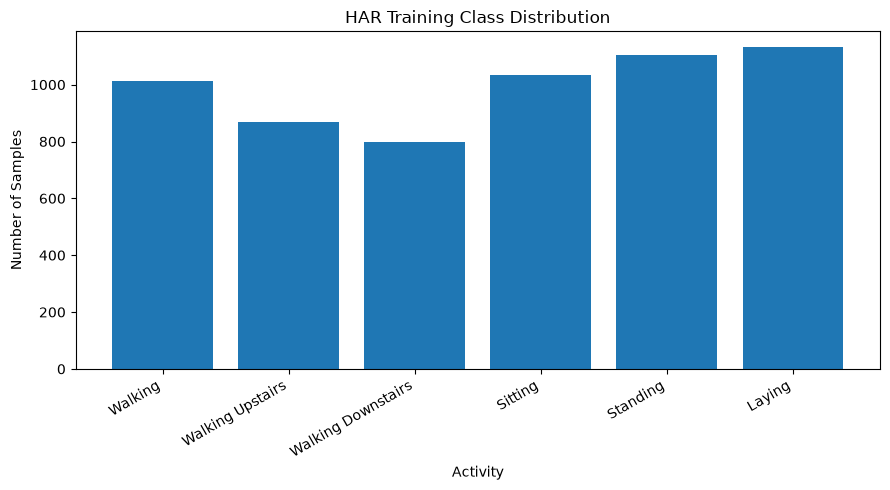

In [10]:
# Plot the class balance

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

class_counts = np.bincount(
    y_train,
    minlength=7
)[1:7]

plt.figure(figsize=(9, 5))

plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "har_class_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Final dataset verification

# Correct dimensions
assert X_train.shape[1:] == (128, 9)
assert X_val.shape[1:] == (128, 9)
assert X_test.shape[1:] == (128, 9)

# Correct number of labels
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Correct activity labels
assert set(np.unique(y_train)).issubset(set(range(1, 7)))
assert set(np.unique(y_val)).issubset(set(range(1, 7)))
assert set(np.unique(y_test)).issubset(set(range(1, 7)))

# Normalization checks
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Subject split
assert len(np.intersect1d(
    train_subjects_final,
    val_subjects_final
)) == 0

print("HAR pipeline verification passed!")


HAR pipeline verification passed!


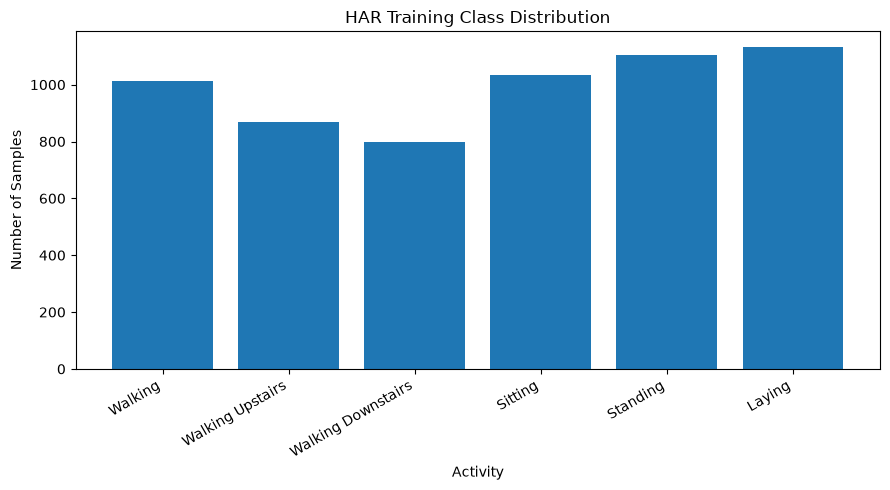

In [12]:
# Save the figures

FIGURES_DIR = Path("problem1/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "class_balance.png",
    dpi=300
)

plt.show()

In [13]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)

    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]

    return x, y.astype(np.float32)

X, y = make_adding(n=1000, T=100, seed=42)

# Correct shapes
assert X.shape == (1000, 100, 2)
assert y.shape == (1000,)

# Exactly two markers
assert np.all(X[:, :, 1].sum(axis=1) == 2)

# One marker in each half
assert np.all(X[:, :50, 1].sum(axis=1) == 1)
assert np.all(X[:, 50:, 1].sum(axis=1) == 1)

# Target correctness
expected = (X[:, :, 0] * X[:, :, 1]).sum(axis=1)

assert np.allclose(y, expected)

print("All adding problem tests passed!")

def create_adding_datasets(T):
    return {
        "train": make_adding(10000, T, 0),
        "val": make_adding(1000, T, 1),
        "test": make_adding(1000, T, 2)
    }

adding_data = create_adding_datasets(T=50)

print("Train:", adding_data["train"][0].shape)
print("Validation:", adding_data["val"][0].shape)
print("Test:", adding_data["test"][0].shape)

All adding problem tests passed!
Train: (10000, 50, 2)
Validation: (1000, 50, 2)
Test: (1000, 50, 2)


PHASE 2

In [14]:
# Convert 3D time-series data into 2D feature vectors

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Test shape:", X_test_flat.shape)

Training shape: (5952, 1152)
Validation shape: (1400, 1152)
Test shape: (2947, 1152)


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_lr = lr_model.predict(X_val_flat)

print("Logistic Regression training completed!")
print("Validation predictions:", y_val_pred_lr[:10])

dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train model
dt_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_dt = dt_model.predict(X_val_flat)

print("Decision Tree training completed!")
print("Validation predictions:", y_val_pred_dt[:10])


Logistic Regression training completed!
Validation predictions: [5 5 5 5 5 1 5 5 5 5]
Decision Tree training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [16]:
# implement KNN
from sklearn.neighbors import KNeighborsClassifier

# Initialize model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train model
knn_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_knn = knn_model.predict(X_val_flat)

print("KNN training completed!")
print("Validation predictions:", y_val_pred_knn[:10])


KNN training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [17]:
from sklearn.naive_bayes import GaussianNB

# Initialize model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_nb = nb_model.predict(X_val_flat)

print("Naive Bayes training completed!")
print("Validation predictions:", y_val_pred_nb[:10])

Naive Bayes training completed!
Validation predictions: [1 5 5 5 5 5 5 5 5 1]


In [18]:
# Support Vector Machine (SVM)
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    probability=True,  # Required for predict_proba() and probability-based AUC
    random_state=42
)
svm_model.fit(X_train_flat, y_train)

y_val_pred_svm = svm_model.predict(X_val_flat)
print("SVM training completed!")
print("Validation predictions:", y_val_pred_svm[:10])


/Users/pavansai/Desktop/2026AJ05432_DNN_Assignment2/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


## Phase 3 — Model Evaluation

Evaluate all five classifiers on the **validation set**. The test set remains untouched until final model selection.

In [19]:
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef
)
import numpy as np
import pandas as pd

def evaluate_model(model, X, y_true, model_name):
    """Return six classification metrics. Supports multiclass datasets."""
    y_pred = model.predict(X)
    classes = model.classes_

    # Obtain stable class scores. GaussianNB can underflow in predict_proba
    # for high-dimensional inputs, so use its log probabilities + softmax.
    if isinstance(model, GaussianNB):
        log_proba = model.predict_log_proba(X)
        log_proba = log_proba - np.max(log_proba, axis=1, keepdims=True)
        y_proba = np.exp(log_proba)
        y_proba = y_proba / y_proba.sum(axis=1, keepdims=True)
    else:
        y_proba = model.predict_proba(X)

    auc = roc_auc_score(
        y_true, y_proba, labels=classes,
        multi_class="ovr", average="macro"
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "MCC": matthews_corrcoef(y_true, y_pred)
    }


In [20]:
# Compare all five models on validation data
results = [
    evaluate_model(lr_model, X_val_flat, y_val, "Logistic Regression"),
    evaluate_model(dt_model, X_val_flat, y_val, "Decision Tree"),
    evaluate_model(knn_model, X_val_flat, y_val, "KNN"),
    evaluate_model(nb_model, X_val_flat, y_val, "Naive Bayes"),
    evaluate_model(svm_model, X_val_flat, y_val, "SVM"),
]

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6014,0.8130,0.5951,0.6014,0.5857,0.5231
1,Decision Tree,0.7171,0.8199,0.7145,0.7171,0.7153,0.6590
2,KNN,0.6943,0.8650,0.8044,0.6943,0.6883,0.6444
3,Naive Bayes,0.7771,0.9219,0.7978,0.7771,0.7743,0.7358
4,SVM,0.8807,0.9862,0.8861,0.8807,0.8812,0.8572


### Metric interpretation
- **Accuracy:** fraction of all predictions that are correct.
- **AUC (macro OvR):** average one-vs-rest ROC AUC across classes; closer to 1 is better.
- **Precision / Recall / F1 (weighted):** class metrics averaged using each class's support.
- **MCC:** balanced correlation between predictions and truth; 1 is perfect, 0 is random-like, -1 is inverse.

Use these validation results to select a model. Do not report validation scores as final test scores.

---
# B — RNN/LSTM/GRU and adding problem


# Problem 1 — RNN, LSTM and GRU on sequences

Run this notebook from the `problem1/` folder (paths are relative). It uses the UCI HAR dataset in `data/har/UCI HAR Dataset/` and the generated adding problem. No pre-trained weights are used.

**Assumptions and deviations (stated once, here):**
- Hidden size `H = 64`, three seeds `0, 1, 2`, Adam with lr `1e-3`, batch `64`, gradient-norm clipping at `1.0` for every main run (so all three models get the same budget).
- Budget: HAR 30 epochs, adding problem 15 epochs. The machine has no GPU, so the epoch counts were chosen to fit a CPU run; they are the same for all three models.
- Model selection uses the **lowest validation loss epoch**. Test metrics are computed once, with that epoch's weights.
- Validation subjects are drawn per seed: `np.random.default_rng(seed).choice(train_subjects, 4, replace=False)`, as the brief specifies.
- The individual ablation (Task 5c) depends on the last digit of the student ID, which is not given to us. Both variants are run so either can be reported.
- `nn.RNN/LSTM/GRU` are used for the comparison experiments only. The cells in Task 2 are written from scratch and are only checked against the library.

In [21]:
import random, time, copy, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.set_num_threads(4)          # leave cores free for other jobs on this machine
DEVICE = torch.device("cpu")      # no CUDA here; see README

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

SEEDS = [0, 1, 2]
H = 64                            # hidden size of the main runs
HAR_EPOCHS = 30
ADD_EPOCHS = 15
BATCH = 64
LR = 1e-3
CLIP = 1.0                        # gradient-norm clipping in all main runs

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RESULTS_PATH = Path("results_problem1.csv")
COLS = ["problem","model","seed","seq_len","test_acc","macro_f1","test_mse","params",
        "sec_per_epoch","val_loss_nats","bits_per_char","notes"]
RESULTS = []

def save_results():
    pd.DataFrame(RESULTS, columns=COLS).to_csv(RESULTS_PATH, index=False)

def add_result(**kw):
    RESULTS.append({c: kw.get(c) for c in COLS}); save_results()

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.15.0 | threads 4


## Task 1 — Data pipelines

**HAR:** 9 channels × 128 steps, 6 classes. Official train/test partitions. The validation split is subject-wise (4 of the 21 training subjects per seed). Normalisation statistics come from the training part only.

In [22]:
HAR_ROOT = Path("data/har/UCI HAR Dataset").resolve()
assert (HAR_ROOT / "train").is_dir(), "UCI HAR not found: see README for the download step"

SIGNALS = ["body_acc_x","body_acc_y","body_acc_z","body_gyro_x","body_gyro_y","body_gyro_z",
           "total_acc_x","total_acc_y","total_acc_z"]

def load_har(split):
    d = HAR_ROOT / split
    X = np.stack([np.loadtxt(d / "Inertial Signals" / f"{s}_{split}.txt") for s in SIGNALS], axis=-1)
    y = np.loadtxt(d / f"y_{split}.txt", dtype=np.int64) - 1        # labels 0..5
    subj = np.loadtxt(d / f"subject_{split}.txt", dtype=np.int64)
    return X.astype(np.float32), y, subj                           # X: (N, 128, 9)

X_tr_all, y_tr_all, subj_tr = load_har("train")
X_te, y_te, subj_te = load_har("test")
print("train", X_tr_all.shape, "test", X_te.shape)

def make_har_data(seed):
    subjects = np.unique(subj_tr)
    val_subjects = np.random.default_rng(seed).choice(subjects, 4, replace=False)
    va = np.isin(subj_tr, val_subjects)
    tr = ~va
    mu = X_tr_all[tr].mean(axis=(0, 1), keepdims=True)          # per channel, training part only
    sd = X_tr_all[tr].std(axis=(0, 1), keepdims=True) + 1e-6
    norm = lambda X: ((X - mu) / sd).astype(np.float32)
    assert set(subj_tr[tr]).isdisjoint(val_subjects), "subject leakage: train/val"
    assert set(val_subjects).isdisjoint(subj_te), "subject leakage: val/test"
    return dict(Xtr=norm(X_tr_all[tr]), ytr=y_tr_all[tr], Xva=norm(X_tr_all[va]), yva=y_tr_all[va],
                Xte=norm(X_te), yte=y_te, val_subjects=val_subjects.tolist())

HAR_DATA = {s: make_har_data(s) for s in SEEDS}
for s in SEEDS:
    D = HAR_DATA[s]
    print(f"seed {s}: val subjects {D['val_subjects']} | train {D['Xtr'].shape} | val {D['Xva'].shape} | test {D['Xte'].shape}")

train (7352, 128, 9) test (2947, 128, 9)
seed 0: val subjects [8, 17, 25, 21] | train (5886, 128, 9) | val (1466, 128, 9) | test (2947, 128, 9)
seed 1: val subjects [25, 16, 29, 15] | train (5905, 128, 9) | val (1447, 128, 9) | test (2947, 128, 9)
seed 2: val subjects [11, 25, 5, 7] | train (6017, 128, 9) | val (1335, 128, 9) | test (2947, 128, 9)


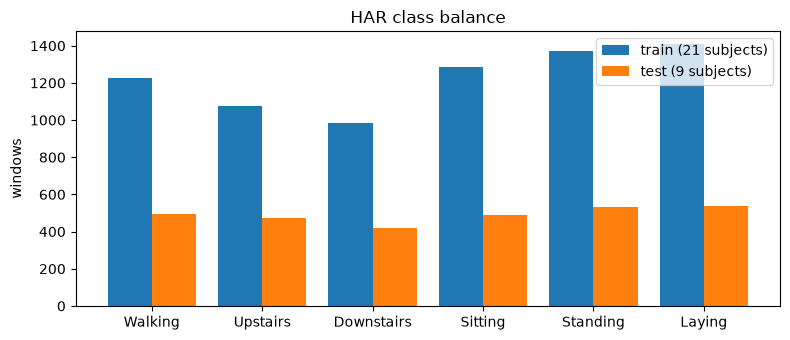

{'Walking': 1226, 'Upstairs': 1073, 'Downstairs': 986, 'Sitting': 1286, 'Standing': 1374, 'Laying': 1407}


In [23]:
NAMES = ["Walking","Upstairs","Downstairs","Sitting","Standing","Laying"]
tr_counts = np.bincount(y_tr_all, minlength=6)
te_counts = np.bincount(y_te, minlength=6)
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(x - 0.2, tr_counts, 0.4, label="train (21 subjects)")
ax.bar(x + 0.2, te_counts, 0.4, label="test (9 subjects)")
ax.set_xticks(x, NAMES); ax.set_ylabel("windows"); ax.set_title("HAR class balance"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "class_balance.png", dpi=160); plt.show()
print(dict(zip(NAMES, tr_counts.tolist())))

**Adding problem:** the generator is the one given in the brief, so the data are identical for every student. Its test is an assert cell placed directly after it.

In [24]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

def test_adding_generator():
    for T in [50, 100, 200, 400]:
        x, y = make_adding(2000, T, seed=0)
        m = x[:, :, 1]
        assert np.all(m.sum(1) == 2), "each sequence needs exactly two markers"
        assert np.all(m[:, :T // 2].sum(1) == 1), "one marker in the first half"
        assert np.all(m[:, T // 2:].sum(1) == 1), "one marker in the second half"
        assert np.allclose(y, (x[:, :, 0] * m).sum(1), atol=1e-6), "target must equal the sum of marked values"
    print("adding-problem generator tests passed")

test_adding_generator()

adding-problem generator tests passed


## Task 2 — RNN, LSTM and GRU cells from scratch

Each cell uses only matrix operations. Gate order follows PyTorch: LSTM `(i, f, g, o)`, GRU `(r, z, n)`. The GRU candidate uses `r * (W_hn h + b_hn)`, which is PyTorch's convention. Copying the library weights into these cells must reproduce the library outputs within 1e-5.

In [25]:
def _affine(x, W, b):
    # x: (B, in), W: (out, in), b: (out,)  ->  (B, out)
    return x @ W.T + b

def _init(*shape):
    k = 1 / math.sqrt(shape[0] if len(shape) == 1 else H)
    return nn.Parameter(torch.empty(*shape).uniform_(-k, k))

class MyRNNCell(nn.Module):
    """h_t = tanh(W_ih x_t + b_ih + W_hh h_{t-1} + b_hh).   x: (B, d), h: (B, h)"""
    def __init__(self, d, h):
        super().__init__()
        self.weight_ih = nn.Parameter(torch.empty(h, d).uniform_(-1/math.sqrt(h), 1/math.sqrt(h)))  # (h, d)
        self.weight_hh = nn.Parameter(torch.empty(h, h).uniform_(-1/math.sqrt(h), 1/math.sqrt(h)))  # (h, h)
        self.bias_ih = nn.Parameter(torch.empty(h).uniform_(-1/math.sqrt(h), 1/math.sqrt(h)))
        self.bias_hh = nn.Parameter(torch.empty(h).uniform_(-1/math.sqrt(h), 1/math.sqrt(h)))
    def forward(self, x, h_prev):
        return torch.tanh(_affine(x, self.weight_ih, self.bias_ih) + _affine(h_prev, self.weight_hh, self.bias_hh))

class MyLSTMCell(nn.Module):
    """Gates (i, f, g, o). W_ih: (4h, d), W_hh: (4h, h)."""
    def __init__(self, d, h):
        super().__init__(); k = 1 / math.sqrt(h)
        self.weight_ih = nn.Parameter(torch.empty(4*h, d).uniform_(-k, k))   # (4h, d)
        self.weight_hh = nn.Parameter(torch.empty(4*h, h).uniform_(-k, k))   # (4h, h)
        self.bias_ih = nn.Parameter(torch.empty(4*h).uniform_(-k, k))
        self.bias_hh = nn.Parameter(torch.empty(4*h).uniform_(-k, k))
    def forward(self, x, state):
        h_prev, c_prev = state                                              # each (B, h)
        gates = _affine(x, self.weight_ih, self.bias_ih) + _affine(h_prev, self.weight_hh, self.bias_hh)  # (B, 4h)
        i, f, g, o = gates.chunk(4, dim=-1)                                 # each (B, h)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c_prev + i * g                                              # (B, h)
        h = o * torch.tanh(c)                                               # (B, h)
        return h, c

class MyGRUCell(nn.Module):
    """Gates (r, z, n). W_ih: (3h, d), W_hh: (3h, h)."""
    def __init__(self, d, h):
        super().__init__(); k = 1 / math.sqrt(h)
        self.weight_ih = nn.Parameter(torch.empty(3*h, d).uniform_(-k, k))   # (3h, d)
        self.weight_hh = nn.Parameter(torch.empty(3*h, h).uniform_(-k, k))   # (3h, h)
        self.bias_ih = nn.Parameter(torch.empty(3*h).uniform_(-k, k))
        self.bias_hh = nn.Parameter(torch.empty(3*h).uniform_(-k, k))
    def forward(self, x, h_prev):
        gi = _affine(x, self.weight_ih, self.bias_ih)                       # (B, 3h)
        gh = _affine(h_prev, self.weight_hh, self.bias_hh)                  # (B, 3h)
        i_r, i_z, i_n = gi.chunk(3, dim=-1)
        h_r, h_z, h_n = gh.chunk(3, dim=-1)
        r = torch.sigmoid(i_r + h_r)
        z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)
        return (1 - z) * n + z * h_prev                                     # (B, h)

class Unrolled(nn.Module):
    """Runs a cell over x: (B, T, d). Keeps every h_t in self.states so that
    retain_grad() on them gives the total gradient dL/dh_t (used in Task 5a)."""
    def __init__(self, cell, h, lstm=False):
        super().__init__(); self.cell = cell; self.h = h; self.lstm = lstm; self.states = []
    def forward(self, x):
        B, T, _ = x.shape
        h0 = x.new_zeros(B, self.h)
        state = (h0, h0.clone()) if self.lstm else h0
        self.states, outs = [], []
        for t in range(T):
            state = self.cell(x[:, t], state)
            h_t = state[0] if self.lstm else state
            outs.append(h_t); self.states.append(h_t)
        return torch.stack(outs, 1), state                                  # (B, T, h), final state

def my_model(kind, d, h):
    if kind == "RNN":  return Unrolled(MyRNNCell(d, h), h)
    if kind == "LSTM": return Unrolled(MyLSTMCell(d, h), h, lstm=True)
    return Unrolled(MyGRUCell(d, h), h)

def lib_layer(kind, d, h):
    return {"RNN": lambda: nn.RNN(d, h, batch_first=True),
            "LSTM": lambda: nn.LSTM(d, h, batch_first=True),
            "GRU": lambda: nn.GRU(d, h, batch_first=True)}[kind]()

def copy_from_library(mine, lib):
    # the library stores the same tensors under *_l0 names, in the same gate order
    c = mine.cell
    c.weight_ih.data.copy_(lib.weight_ih_l0.data); c.weight_hh.data.copy_(lib.weight_hh_l0.data)
    c.bias_ih.data.copy_(lib.bias_ih_l0.data);     c.bias_hh.data.copy_(lib.bias_hh_l0.data)
    return mine

In [26]:
def verify_cell(kind, d=9, h=64, B=32, T=128, tol=1e-5):
    set_seed(0)
    lib = lib_layer(kind, d, h).eval()
    mine = copy_from_library(my_model(kind, d, h), lib).eval()
    x = torch.randn(B, T, d)                                    # random batch
    with torch.no_grad():
        out_lib, st_lib = lib(x)
        out_my, st_my = mine(x)
    d_out = (out_lib - out_my).abs().max().item()
    if kind == "LSTM":
        d_state = max((st_lib[0][0] - st_my[0]).abs().max().item(),
                      (st_lib[1][0] - st_my[1]).abs().max().item())
    else:
        d_state = (st_lib[0] - st_my).abs().max().item()
    print(f"{kind:4s}: max |output diff| = {d_out:.2e}   max |final state diff| = {d_state:.2e}")
    assert d_out < tol and d_state < tol, f"{kind} does not match the library"

for k in ["RNN", "LSTM", "GRU"]:
    verify_cell(k)
print("All three cells match nn.RNN / nn.LSTM / nn.GRU within 1e-5.")

RNN : max |output diff| = 2.68e-07   max |final state diff| = 1.79e-07
LSTM: max |output diff| = 5.96e-08   max |final state diff| = 8.94e-08
GRU : max |output diff| = 9.69e-08   max |final state diff| = 5.96e-08
All three cells match nn.RNN / nn.LSTM / nn.GRU within 1e-5.


**Parameter counts for d = 9, h = 64, by hand.** With one bias vector, the RNN has `h(d+h) + h = 64·73 + 64 = 4,736`. The LSTM has 4 such blocks (`4·4,736 = 18,944`) and the GRU has 3 (`3·4,736 = 14,208`). PyTorch keeps two bias vectors (`bias_ih` and `bias_hh`), which adds `h`, `4h` and `3h` respectively: `4,800`, `19,200` and `14,400`. The cells above also hold two bias vectors, so they match PyTorch's count.

In [27]:
d, h = 9, 64
hand_one_bias = {"RNN": h*(d+h)+h, "LSTM": 4*(h*(d+h)+h), "GRU": 3*(h*(d+h)+h)}
lib_counts = {k: n_params(lib_layer(k, d, h)) for k in ["RNN","LSTM","GRU"]}
my_counts = {k: n_params(my_model(k, d, h)) for k in ["RNN","LSTM","GRU"]}
print(pd.DataFrame({"hand (one bias)": hand_one_bias, "my cells": my_counts, "nn.* layer": lib_counts}))
assert hand_one_bias == {"RNN": 4736, "LSTM": 18944, "GRU": 14208}
assert lib_counts == {"RNN": 4800, "LSTM": 19200, "GRU": 14400}
assert my_counts == lib_counts
print("Parameter counts reconcile: hand derivation + one extra bias vector per gate block = PyTorch.")

      hand (one bias)  my cells  nn.* layer
RNN              4736      4800        4800
LSTM            18944     19200       19200
GRU             14208     14400       14400
Parameter counts reconcile: hand derivation + one extra bias vector per gate block = PyTorch.


## Task 3 — HAR classification

Each model reads the 128 steps and classifies from the last hidden state with a linear head. `params` in `results_problem1.csv` is the whole model, including the head. The recurrent-layer count is printed separately.

In [28]:
class RecClassifier(nn.Module):
    """Recurrent layer (library) -> last hidden state -> linear head."""
    def __init__(self, kind, d_in, h, n_out):
        super().__init__()
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](d_in, h, batch_first=True)
        self.head = nn.Linear(h, n_out)
    def forward(self, x):                # x: (B, T, d_in)
        out, _ = self.rnn(x)             # out: (B, T, h)
        return self.head(out[:, -1])     # (B, n_out)

def set_lstm_forget_bias(model, value):
    # PyTorch LSTM gate order is (i, f, g, o): the forget gate is the second quarter
    hh = model.rnn.hidden_size
    with torch.no_grad():
        model.rnn.bias_ih_l0[hh:2*hh].fill_(value)
        model.rnn.bias_hh_l0[hh:2*hh].fill_(0.0)     # effective forget bias = value

CE_LOSS = lambda p, y: F.cross_entropy(p, y)
MSE_LOSS = lambda p, y: F.mse_loss(p.squeeze(-1), y)

@torch.no_grad()
def predict(model, data, loss_fn):
    model.eval()
    X, y = torch.tensor(data[0]), torch.tensor(data[1])
    outs = torch.cat([model(X[i:i+512]) for i in range(0, len(X), 512)])
    loss = loss_fn(outs, y).item()
    preds = outs.argmax(-1).numpy() if loss_fn is CE_LOSS else outs.squeeze(-1).numpy()
    return loss, preds

def run_model(model, tr, va, loss_fn, epochs, clip=CLIP, seed=0):
    """Adam training; keep the epoch with the lowest validation loss (test data is never used)."""
    set_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    Xtr, ytr = torch.tensor(tr[0]), torch.tensor(tr[1])
    hist = {"train": [], "val": [], "epoch_sec": []}
    best = {"val": float("inf"), "state": None, "epoch": -1}
    for ep in range(epochs):
        model.train(); t0 = time.time(); total = 0.0
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), BATCH):
            idx = perm[i:i+BATCH]
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step(); total += loss.item() * len(idx)
        hist["epoch_sec"].append(time.time() - t0)
        hist["train"].append(total / len(Xtr))
        vl, _ = predict(model, va, loss_fn)
        hist["val"].append(vl)
        if vl < best["val"]:
            best = {"val": vl, "state": copy.deepcopy(model.state_dict()), "epoch": ep}
    if best["state"] is not None:
        model.load_state_dict(best["state"])
    return model, hist, best

HAR_RES = {}
def train_har(kind, hh, s, clip=CLIP, note=""):
    D = HAR_DATA[s]
    set_seed(s)
    model = RecClassifier(kind, 9, hh, 6)
    n_par = n_params(model)
    model, hist, best = run_model(model, (D["Xtr"], D["ytr"]), (D["Xva"], D["yva"]), CE_LOSS, HAR_EPOCHS, clip=clip, seed=s)
    _, pred = predict(model, (D["Xte"], D["yte"]), CE_LOSS)
    _, pred_va = predict(model, (D["Xva"], D["yva"]), CE_LOSS)
    r = dict(model=model, hist=hist, best_epoch=best["epoch"], params=n_par, pred=pred,
             acc=accuracy_score(D["yte"], pred), f1=f1_score(D["yte"], pred, average="macro"),
             val_f1=f1_score(D["yva"], pred_va, average="macro"), sec=float(np.mean(hist["epoch_sec"])))
    add_result(problem=1, model=kind, seed=s, seq_len=128, test_acc=r["acc"], macro_f1=r["f1"],
               params=n_par, sec_per_epoch=r["sec"],
               notes=f"HAR; H={hh}; epochs={HAR_EPOCHS}; clip={clip}; best_epoch={best['epoch']}; val_macro_f1={r['val_f1']:.4f}{note}")
    return r

for kind in ["RNN", "LSTM", "GRU"]:
    for s in SEEDS:
        HAR_RES[(kind, H, s)] = train_har(kind, H, s)
        r = HAR_RES[(kind, H, s)]
        print(f"HAR {kind:4s} seed {s}: test acc {r['acc']:.4f}  macro-F1 {r['f1']:.4f}  best epoch {r['best_epoch']}  {r['sec']:.2f}s/epoch")

HAR RNN  seed 0: test acc 0.8541  macro-F1 0.8503  best epoch 13  0.52s/epoch
HAR RNN  seed 1: test acc 0.8473  macro-F1 0.8486  best epoch 15  0.50s/epoch
HAR RNN  seed 2: test acc 0.8497  macro-F1 0.8498  best epoch 25  0.48s/epoch
HAR LSTM seed 0: test acc 0.8880  macro-F1 0.8890  best epoch 29  1.38s/epoch
HAR LSTM seed 1: test acc 0.8860  macro-F1 0.8854  best epoch 25  1.38s/epoch
HAR LSTM seed 2: test acc 0.8856  macro-F1 0.8856  best epoch 6  1.41s/epoch
HAR GRU  seed 0: test acc 0.8928  macro-F1 0.8922  best epoch 19  1.14s/epoch
HAR GRU  seed 1: test acc 0.8887  macro-F1 0.8876  best epoch 5  1.14s/epoch
HAR GRU  seed 2: test acc 0.8799  macro-F1 0.8792  best epoch 5  1.16s/epoch


,model,params (total),test acc (%),test macro-F1,sec/epoch,val macro-F1 (mean)
0,RNN,5190,85.04 ± 0.34,0.8495 ± 0.0009,0.50,0.8682
1,LSTM,19590,88.66 ± 0.13,0.8867 ± 0.0020,1.39,0.9129
2,GRU,14790,88.71 ± 0.66,0.8863 ± 0.0066,1.14,0.9116


Best HAR model (by validation macro-F1): LSTM


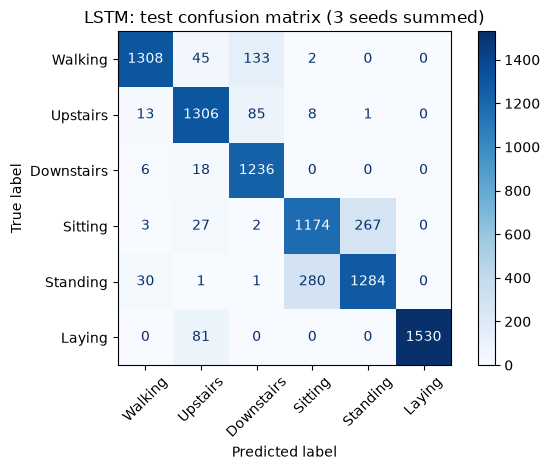

In [29]:
rows = []
for kind in ["RNN", "LSTM", "GRU"]:
    rs = [HAR_RES[(kind, H, s)] for s in SEEDS]
    acc = np.array([r["acc"] for r in rs]); f1s = np.array([r["f1"] for r in rs])
    rows.append({"model": kind, "params (total)": rs[0]["params"],
                 "test acc (%)": f"{100*acc.mean():.2f} ± {100*acc.std(ddof=1):.2f}",
                 "test macro-F1": f"{f1s.mean():.4f} ± {f1s.std(ddof=1):.4f}",
                 "sec/epoch": round(float(np.mean([r['sec'] for r in rs])), 2),
                 "val macro-F1 (mean)": round(float(np.mean([r["val_f1"] for r in rs])), 4)})
har_table = pd.DataFrame(rows)
display(har_table)
har_table.to_csv(FIG.parent / "har_summary_table.csv", index=False)

best_kind = max(["RNN","LSTM","GRU"], key=lambda k: np.mean([HAR_RES[(k, H, s)]["val_f1"] for s in SEEDS]))
print("Best HAR model (by validation macro-F1):", best_kind)
cm = sum(confusion_matrix(HAR_DATA[s]["yte"], HAR_RES[(best_kind, H, s)]["pred"], labels=range(6)) for s in SEEDS)
disp = ConfusionMatrixDisplay(cm, display_labels=NAMES)
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title(f"{best_kind}: test confusion matrix (3 seeds summed)")
plt.tight_layout(); plt.savefig(FIG / "har_confusion_best.png", dpi=160); plt.show()

In [30]:
# Classical baselines from the earlier notebook, for reference (not the recurrent comparison)
classical = Path("test_results.csv")
if classical.exists():
    print("Classical best (SVM) test metrics from classical_baselines.ipynb:")
    display(pd.read_csv(classical).round(4))

Classical best (SVM) test metrics from classical_baselines.ipynb:


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.888,0.9885,0.8927,0.888,0.8886,0.8663


## Task 4 — Adding problem, T = 50, 100, 200, 400

Three models × three seeds × four lengths. The constant-prediction baseline (predict 1.0) is printed for each T. A run is *solved* if its test MSE is below 0.05.

In [31]:
TS = [50, 100, 200, 400]
ADD_DATA = {T: (make_adding(10000, T, seed=0), make_adding(1000, T, seed=1), make_adding(1000, T, seed=2)) for T in TS}
BASELINE = {}
for T in TS:
    tr, va, te = ADD_DATA[T]
    BASELINE[T] = float(np.mean((te[1] - 1.0) ** 2))
    print(f"T={T:3d}: constant-1.0 baseline test MSE = {BASELINE[T]:.4f}")

ADD_RES = {}
INIT_SNAPSHOT = {}
def train_adding(kind, T, s, hh=H, clip=CLIP, forget_bias=None, note=""):
    tr, va, te = ADD_DATA[T]
    set_seed(s)
    model = RecClassifier(kind, 2, hh, 1)
    if forget_bias is not None and kind == "LSTM":
        set_lstm_forget_bias(model, forget_bias)
    if T == 100 and s == 0 and forget_bias is None and clip == CLIP and hh == H:
        INIT_SNAPSHOT[kind] = copy.deepcopy(model)          # untrained weights for Task 5a
    n_par = n_params(model)
    model, hist, best = run_model(model, tr, va, MSE_LOSS, ADD_EPOCHS, clip=clip, seed=s)
    test_mse, _ = predict(model, te, MSE_LOSS)
    solved = bool(test_mse < 0.05)
    r = dict(model=model, hist=hist, mse=test_mse, solved=solved, params=n_par, best_epoch=best["epoch"])
    add_result(problem=1, model=kind, seed=s, seq_len=T, test_mse=test_mse, params=n_par,
               sec_per_epoch=float(np.mean(hist["epoch_sec"])),
               notes=f"adding; H={hh}; epochs={ADD_EPOCHS}; clip={clip}; best_epoch={best['epoch']}; solved={solved}; baseline_mse={BASELINE[T]:.4f}{note}")
    return r

for T in TS:
    for kind in ["RNN", "LSTM", "GRU"]:
        for s in SEEDS:
            ADD_RES[(kind, T, s)] = train_adding(kind, T, s)
            r = ADD_RES[(kind, T, s)]
            print(f"T={T:3d} {kind:4s} seed {s}: test MSE {r['mse']:.4f}  {'solved' if r['solved'] else 'not solved'}  ({np.mean(r['hist']['epoch_sec']):.1f}s/epoch)")

T= 50: constant-1.0 baseline test MSE = 0.1754
T=100: constant-1.0 baseline test MSE = 0.1697
T=200: constant-1.0 baseline test MSE = 0.1679
T=400: constant-1.0 baseline test MSE = 0.1527
T= 50 RNN  seed 0: test MSE 0.1748  not solved  (0.3s/epoch)
T= 50 RNN  seed 1: test MSE 0.1747  not solved  (0.3s/epoch)
T= 50 RNN  seed 2: test MSE 0.1749  not solved  (0.3s/epoch)
T= 50 LSTM seed 0: test MSE 0.0170  solved  (0.9s/epoch)
T= 50 LSTM seed 1: test MSE 0.0495  solved  (0.9s/epoch)
T= 50 LSTM seed 2: test MSE 0.0110  solved  (0.9s/epoch)
T= 50 GRU  seed 0: test MSE 0.0028  solved  (0.7s/epoch)
T= 50 GRU  seed 1: test MSE 0.0015  solved  (0.7s/epoch)
T= 50 GRU  seed 2: test MSE 0.0021  solved  (0.7s/epoch)
T=100 RNN  seed 0: test MSE 0.1705  not solved  (0.6s/epoch)
T=100 RNN  seed 1: test MSE 0.1700  not solved  (0.6s/epoch)
T=100 RNN  seed 2: test MSE 0.1701  not solved  (0.6s/epoch)
T=100 LSTM seed 0: test MSE 0.1694  not solved  (1.8s/epoch)
T=100 LSTM seed 1: test MSE 0.1695  not sol

,model,T,test MSE,solved (of 3),baseline MSE
0,RNN,50,0.1748 ± 0.0001,0,0.1754
1,RNN,100,0.1702 ± 0.0003,0,0.1697
2,RNN,200,0.1685 ± 0.0003,0,0.1679
3,RNN,400,0.1539 ± 0.0005,0,0.1527
4,LSTM,50,0.0258 ± 0.0207,3,0.1754
5,LSTM,100,0.1697 ± 0.0003,0,0.1697
6,LSTM,200,0.1683 ± 0.0001,0,0.1679
7,LSTM,400,0.1536 ± 0.0001,0,0.1527
8,GRU,50,0.0021 ± 0.0007,3,0.1754
9,GRU,100,0.0020 ± 0.0001,3,0.1697


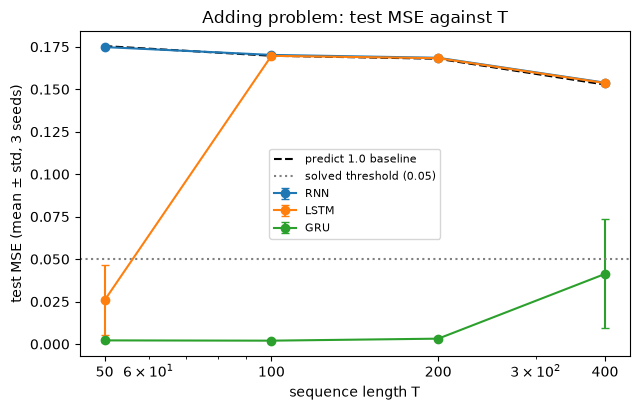

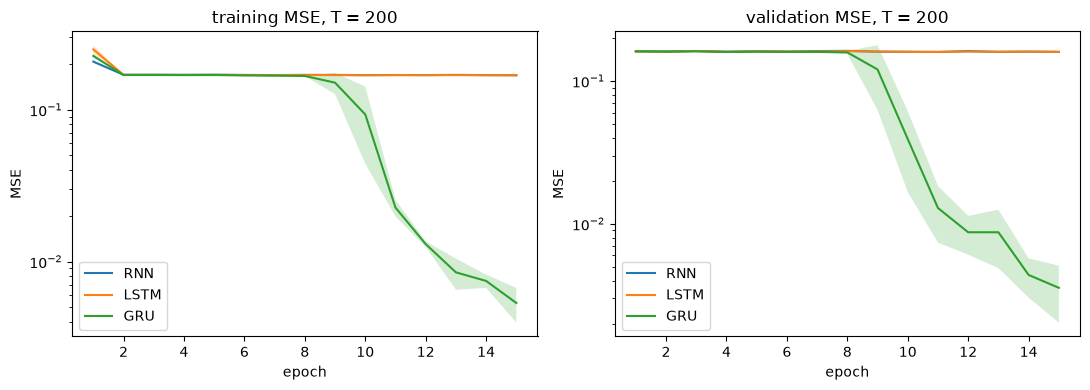

In [32]:
rows = []
for kind in ["RNN","LSTM","GRU"]:
    for T in TS:
        m = np.array([ADD_RES[(kind, T, s)]["mse"] for s in SEEDS])
        rows.append({"model": kind, "T": T,
                     "test MSE": f"{m.mean():.4f} ± {m.std(ddof=1):.4f}",
                     "solved (of 3)": sum(ADD_RES[(kind, T, s)]["solved"] for s in SEEDS),
                     "baseline MSE": round(BASELINE[T], 4)})
add_table = pd.DataFrame(rows)
display(add_table)
add_table.to_csv(FIG.parent / "adding_summary_table.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for kind in ["RNN","LSTM","GRU"]:
    mu = [np.mean([ADD_RES[(kind, T, s)]["mse"] for s in SEEDS]) for T in TS]
    sd = [np.std([ADD_RES[(kind, T, s)]["mse"] for s in SEEDS], ddof=1) for T in TS]
    ax.errorbar(TS, mu, yerr=sd, marker="o", capsize=3, label=kind)
ax.plot(TS, [BASELINE[T] for T in TS], "k--", label="predict 1.0 baseline")
ax.axhline(0.05, color="grey", ls=":", label="solved threshold (0.05)")
ax.set_xscale("log"); ax.set_xticks(TS, [str(T) for T in TS])
ax.set_xlabel("sequence length T"); ax.set_ylabel("test MSE (mean ± std, 3 seeds)")
ax.set_title("Adding problem: test MSE against T"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "adding_mse_vs_T.png", dpi=160); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, ADD_EPOCHS + 1)
for kind in ["RNN","LSTM","GRU"]:
    tr_c = np.array([ADD_RES[(kind, 200, s)]["hist"]["train"] for s in SEEDS])
    va_c = np.array([ADD_RES[(kind, 200, s)]["hist"]["val"] for s in SEEDS])
    for ax, c in zip(axes, [tr_c, va_c]):
        ax.plot(ep, c.mean(0), label=kind)
        ax.fill_between(ep, c.mean(0) - c.std(0, ddof=1), c.mean(0) + c.std(0, ddof=1), alpha=0.2)
axes[0].set_title("training MSE, T = 200"); axes[1].set_title("validation MSE, T = 200")
for ax in axes:
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "adding_learning_curves_T200.png", dpi=160); plt.show()

## Task 5 — Gradients, ablations, hidden-size sweep

**(a)** Gradient norms ‖∂L/∂h_t‖ for T = 100, before and after training (seed 0 weights from Task 4). The profile uses the from-scratch unrolled cells with the trained library weights copied in, so that every h_t receives its total gradient. The profile is averaged over 256 held-out sequences.

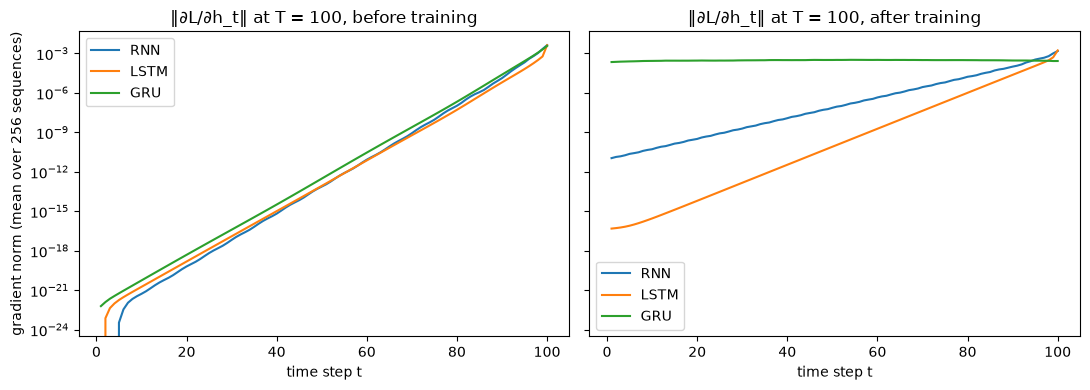

      |grad| at t=1 / t=T (after)  |grad| at t=T (after)
RNN                  7.233786e-09               0.001519
LSTM                 2.885134e-14               0.001679
GRU                  8.331016e-01               0.000265


In [33]:
Xg, yg = make_adding(256, 100, seed=3)
Xg_t, yg_t = torch.tensor(Xg), torch.tensor(yg)

def grad_profile(my, head, X, y):
    my.zero_grad()
    out, _ = my(X)                                       # out: (B, T, h)
    for h_t in my.states: h_t.retain_grad()
    loss = F.mse_loss(head(out[:, -1]).squeeze(-1), y)
    loss.backward()
    norms = torch.stack([h_t.grad.norm(dim=-1) for h_t in my.states], 1)   # (B, T)
    return norms.mean(0).detach().numpy()

PROF = {}
for kind in ["RNN","LSTM","GRU"]:
    before = INIT_SNAPSHOT[kind]
    after = ADD_RES[(kind, 100, 0)]["model"]
    PROF[(kind, "before")] = grad_profile(copy_from_library(my_model(kind, 2, H), before.rnn), before.head, Xg_t, yg_t)
    PROF[(kind, "after")] = grad_profile(copy_from_library(my_model(kind, 2, H), after.rnn), after.head, Xg_t, yg_t)
    # the from-scratch cell must reproduce the trained library layer on these weights
    mine = copy_from_library(my_model(kind, 2, H), after.rnn).eval()
    with torch.no_grad():
        diff = (mine(Xg_t)[0] - after.rnn(Xg_t)[0]).abs().max().item()
    assert diff < 1e-5, f"{kind}: trained-weight mismatch {diff}"

t = np.arange(1, 101)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, when in zip(axes, ["before", "after"]):
    for kind in ["RNN","LSTM","GRU"]:
        ax.semilogy(t, PROF[(kind, when)], label=kind)
    ax.set_title(f"‖∂L/∂h_t‖ at T = 100, {when} training"); ax.set_xlabel("time step t"); ax.legend()
axes[0].set_ylabel("gradient norm (mean over 256 sequences)")
plt.tight_layout(); plt.savefig(FIG / "grad_norm_vs_t_T100.png", dpi=160); plt.show()

print(pd.DataFrame({k: {"|grad| at t=1 / t=T (after)": PROF[(k,'after')][0] / PROF[(k,'after')][-1],
                        "|grad| at t=T (after)": PROF[(k,'after')][-1]} for k in ["RNN","LSTM","GRU"]}).T)

**(b) Hidden-size sweep** for LSTM and GRU on HAR, `H ∈ {16, 32, 64, 128}`. H = 64 is taken from the main runs in Task 3 (same settings).

sweep LSTM H= 16 seed 0: test acc 0.8612  params 1830  0.62s/epoch
sweep LSTM H= 32 seed 0: test acc 0.8707  params 5702  0.81s/epoch
sweep LSTM H=128 seed 0: test acc 0.9026  params 71942  2.27s/epoch
sweep GRU  H= 16 seed 0: test acc 0.8744  params 1398  0.66s/epoch
sweep GRU  H= 32 seed 0: test acc 0.9030  params 4326  0.76s/epoch
sweep GRU  H=128 seed 0: test acc 0.9206  params 54150  1.85s/epoch


,model,H,params (total),test acc (%) seed 0,sec/epoch
0,LSTM,16,1830,86.12,0.62
1,LSTM,32,5702,87.07,0.81
2,LSTM,64,19590,88.80,1.38
3,LSTM,128,71942,90.26,2.27
4,GRU,16,1398,87.44,0.66
5,GRU,32,4326,90.30,0.76
6,GRU,64,14790,89.28,1.14
7,GRU,128,54150,92.06,1.85


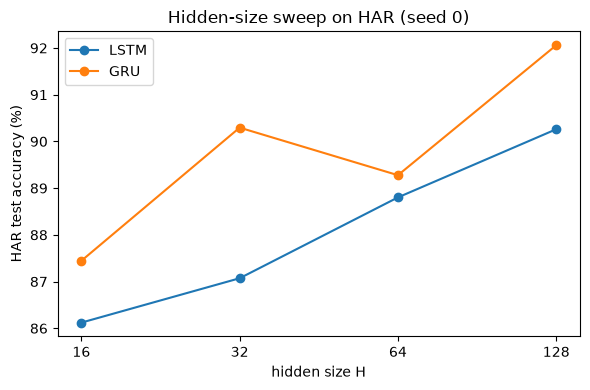

In [34]:
SWEEP_H = [16, 32, 64, 128]
SWEEP_SEEDS = [0]                 # one seed for the sweep to save time (H=64 uses seed 0 too)
for kind in ["LSTM", "GRU"]:
    for hh in SWEEP_H:
        if hh == H:
            continue
        for s in SWEEP_SEEDS:
            HAR_RES[(kind, hh, s)] = train_har(kind, hh, s, note=f"; sweep")
            r = HAR_RES[(kind, hh, s)]
            print(f"sweep {kind:4s} H={hh:3d} seed {s}: test acc {r['acc']:.4f}  params {r['params']}  {r['sec']:.2f}s/epoch")

rows = []
for kind in ["LSTM","GRU"]:
    for hh in SWEEP_H:
        rs = [HAR_RES[(kind, hh, s)] for s in SWEEP_SEEDS]
        acc = np.array([r["acc"] for r in rs])
        rows.append({"model": kind, "H": hh, "params (total)": rs[0]["params"],
                     "test acc (%) seed 0": f"{100*acc.mean():.2f}",
                     "sec/epoch": round(float(np.mean([r['sec'] for r in rs])), 2)})
sweep_table = pd.DataFrame(rows)
display(sweep_table)
sweep_table.to_csv(FIG.parent / "hidden_sweep_table.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
for kind in ["LSTM","GRU"]:
    mu = [100*np.mean([HAR_RES[(kind, hh, s)]["acc"] for s in SWEEP_SEEDS]) for hh in SWEEP_H]
    ax.plot(SWEEP_H, mu, marker="o", label=kind)
ax.set_xscale("log", base=2); ax.set_xticks(SWEEP_H, [str(h) for h in SWEEP_H])
ax.set_xlabel("hidden size H"); ax.set_ylabel("HAR test accuracy (%)"); ax.legend()
ax.set_title("Hidden-size sweep on HAR (seed 0)")
plt.tight_layout(); plt.savefig(FIG / "hidden_sweep_har.png", dpi=160); plt.show()

**(c) Individual ablation.** The brief assigns one of these by the last digit of the student ID. The student ID is not known to this notebook, so both are run at T = 200, three seeds each:
- even last digit → gradient clipping (norm 1.0 vs none) for the vanilla RNN;
- odd last digit → LSTM forget-gate bias 0 vs 1.

The clip = 1.0 RNN runs are the Task 4 main runs (identical settings), so they are reused.

,ablation,condition,test MSE,solved (of 3)
0,rnn_clip,clip 1.0,0.1685 ± 0.0003,0
1,rnn_clip,no clip,0.1684 ± 0.0003,0
2,lstm_forget,forget bias 0,0.1683 ± 0.0001,0
3,lstm_forget,forget bias 1,0.1684 ± 0.0001,0


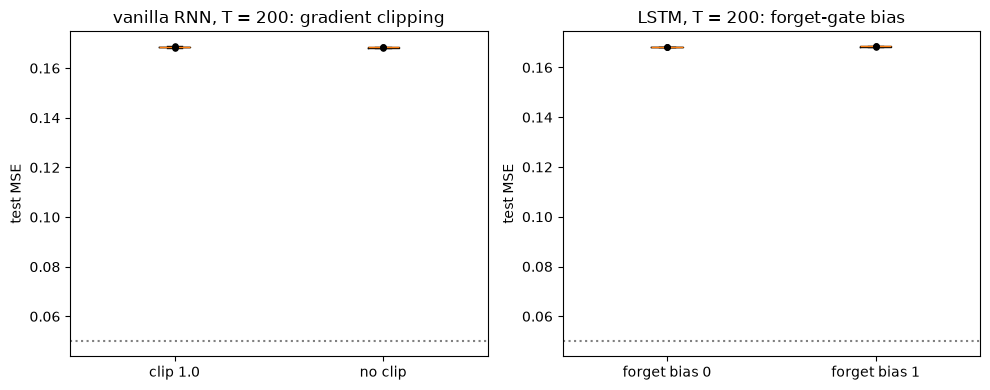

In [35]:
ABL = {"rnn_clip": {}, "lstm_forget": {}}
for s in SEEDS:
    ABL["rnn_clip"][("clip 1.0", s)] = ADD_RES[("RNN", 200, s)]
    ABL["rnn_clip"][("no clip", s)] = train_adding("RNN", 200, s, clip=None, note="; ablation=no_clip")
    ABL["lstm_forget"][("forget bias 0", s)] = train_adding("LSTM", 200, s, forget_bias=0.0, note="; ablation=forget_bias_0")
    ABL["lstm_forget"][("forget bias 1", s)] = train_adding("LSTM", 200, s, forget_bias=1.0, note="; ablation=forget_bias_1")

abl_rows = []
for name, group in ABL.items():
    for cond in sorted({c for c, _ in group}):
        m = np.array([group[(cond, s)]["mse"] for s in SEEDS])
        abl_rows.append({"ablation": name, "condition": cond, "test MSE": f"{np.nanmean(m):.4f} ± {np.nanstd(m, ddof=1):.4f}",
                         "solved (of 3)": sum(group[(cond, s)]["solved"] for s in SEEDS)})
abl_table = pd.DataFrame(abl_rows)
display(abl_table)
abl_table.to_csv(FIG.parent / "ablation_table.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, title) in zip(axes, [("rnn_clip", "vanilla RNN, T = 200: gradient clipping"),
                                    ("lstm_forget", "LSTM, T = 200: forget-gate bias")]):
    conds = sorted({c for c, _ in ABL[name]})
    vals = [[ABL[name][(c, s)]["mse"] for s in SEEDS] for c in conds]
    ax.boxplot(vals, tick_labels=conds)
    for i, v in enumerate(vals):
        ax.scatter([i+1]*len(v), v, color="k", zorder=3, s=14)
    ax.axhline(0.05, color="grey", ls=":"); ax.set_title(title); ax.set_ylabel("test MSE")
plt.tight_layout(); plt.savefig(FIG / "ablation_T200.png", dpi=160); plt.show()

In [36]:
save_results()
print("Rows written:", len(RESULTS), "->", RESULTS_PATH.resolve())
print(pd.read_csv(RESULTS_PATH).groupby(["model","seq_len"], dropna=False).size().head(20))

Rows written: 60 -> /Users/pavansai/Desktop/2026AJ05432_DNN_Assignment2/problem1/results_problem1.csv
model  seq_len
GRU    50         3
       100        3
       128        6
       200        3
       400        3
LSTM   50         3
       100        3
       128        6
       200        9
       400        3
RNN    50         3
       100        3
       128        3
       200        6
       400        3
dtype: int64


---
# C — Validation-based selection and final test evaluation


# Model Selection & Final Evaluation

> **Continue from `problem1_phase2_completed.ipynb`.** Run that notebook first, then run every cell below in order. This notebook assumes the trained models and arrays (`X_val_flat`, `y_val`, `X_test_flat`, `y_test`) are already available.

This section completes the workflow after the Phase 2 validation comparison. The validation set is used for model selection; the test set is reserved for one final evaluation.

## Step 1 — Select the best model using validation metrics

We compare models using more than accuracy. The code below selects the model with the highest **validation MCC** as a default selection criterion (MCC considers all classes and is useful when class distribution is uneven). Review the complete table and justify the choice in your report; you may choose another metric if the assignment specifies one.

In [37]:
# Re-create the model registry (these models should already be trained)
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "KNN": knn_model,
    "Naive Bayes": nb_model,
    "SVM": svm_model,
}

# Sort validation results by MCC (then F1 as a tie-breaker)
validation_ranked = results_df.sort_values(
    by=["MCC", "F1"], ascending=False
).reset_index(drop=True)

display(validation_ranked.round(4))

best_model_name = validation_ranked.loc[0, "Model"]
best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: highest validation MCC (F1 tie-breaker)")

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.8807,0.9862,0.8861,0.8807,0.8812,0.8572
1,Naive Bayes,0.7771,0.9219,0.7978,0.7771,0.7743,0.7358
2,Decision Tree,0.7171,0.8199,0.7145,0.7171,0.7153,0.6590
3,KNN,0.6943,0.8650,0.8044,0.6943,0.6883,0.6444
4,Logistic Regression,0.6014,0.8130,0.5951,0.6014,0.5857,0.5231


Selected model: SVM
Selection criterion: highest validation MCC (F1 tie-breaker)


## Step 2 — Confusion matrix for the selected model

A confusion matrix shows which activities are correctly classified and which activities are confused with one another. Rows are true labels and columns are predicted labels.

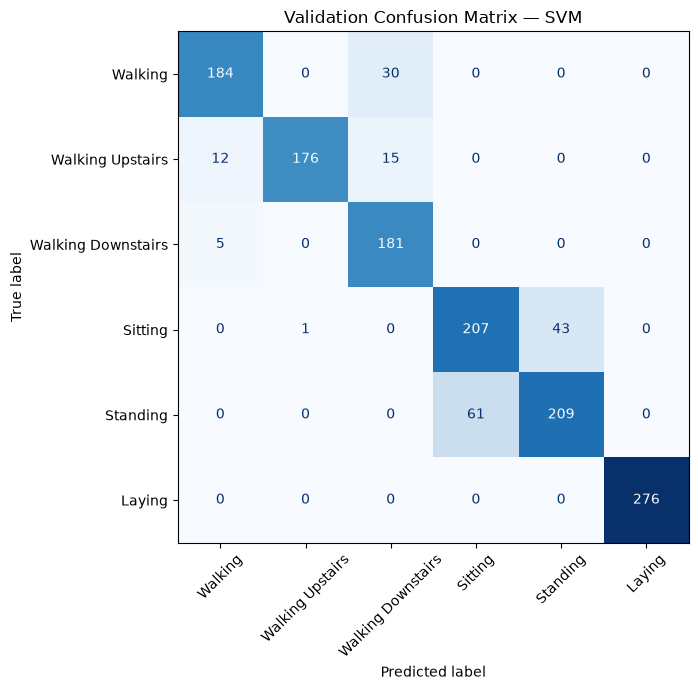

Validation confusion matrix:


,Walking,Walking Upstairs,Walking Downstairs,Sitting,Standing,Laying
Walking,184,0,30,0,0,0
Walking Upstairs,12,176,15,0,0,0
Walking Downstairs,5,0,181,0,0,0
Sitting,0,1,0,207,43,0
Standing,0,0,0,61,209,0
Laying,0,0,0,0,0,276


In [38]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

activity_names = [
    "Walking", "Walking Upstairs", "Walking Downstairs",
    "Sitting", "Standing", "Laying"
]
class_labels = np.arange(1, 7)

y_val_pred_best = best_model.predict(X_val_flat)
cm_val = confusion_matrix(y_val, y_val_pred_best, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_val,
    display_labels=activity_names
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Validation Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print("Validation confusion matrix:")
display(pd.DataFrame(cm_val, index=activity_names, columns=activity_names))

## Step 3 — Final evaluation on the test set (once)

**Do not use test metrics to change/select the model.** After validation-based selection, evaluate the chosen model on the held-out test set exactly once.

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM (Final Test),0.888,0.9885,0.8927,0.888,0.8886,0.8663


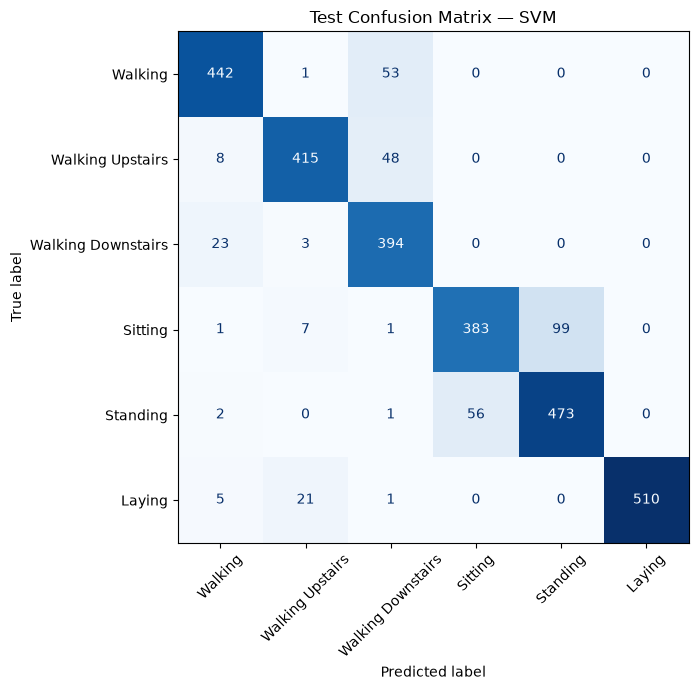

In [39]:
test_result = evaluate_model(
    best_model, X_test_flat, y_test,
    f"{best_model_name} (Final Test)"
)

test_results_df = pd.DataFrame([test_result])
display(test_results_df.round(4))

y_test_pred_best = best_model.predict(X_test_flat)
cm_test = confusion_matrix(y_test, y_test_pred_best, labels=class_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=activity_names
)
fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## Step 4 — Save the selected model and evaluation outputs

The files are written into `problem1/artifacts/`. Keep these artifacts with your submission/repository as required.

In [40]:
from pathlib import Path
import joblib

ARTIFACTS_DIR = Path("problem1/artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACTS_DIR / "best_har_model.joblib"
joblib.dump(best_model, model_path)

validation_ranked.to_csv(ARTIFACTS_DIR / "validation_model_comparison.csv", index=False)
test_results_df.to_csv(ARTIFACTS_DIR / "final_test_metrics.csv", index=False)
pd.DataFrame(cm_test, index=activity_names, columns=activity_names).to_csv(
    ARTIFACTS_DIR / "test_confusion_matrix.csv"
)

print("Saved model:", model_path)
print("Saved validation comparison, final test metrics, and test confusion matrix.")

Saved model: problem1/artifacts/best_har_model.joblib
Saved validation comparison, final test metrics, and test confusion matrix.


In [42]:
print("Training label counts:")
display(pd.Series(y_train).value_counts().sort_index().rename(index=dict(zip(range(1, 7), activity_names))).to_frame("count"))

print("Validation label counts:")
display(pd.Series(y_val).value_counts().sort_index().rename(index=dict(zip(range(1, 7), activity_names))).to_frame("count"))

print("Test label counts:")
display(pd.Series(y_test).value_counts().sort_index().rename(index=dict(zip(range(1, 7), activity_names))).to_frame("count"))

Training label counts:


,count
Walking,1012
Walking Upstairs,870
Walking Downstairs,800
Sitting,1035
Standing,1104
Laying,1131


Validation label counts:


,count
Walking,214
Walking Upstairs,203
Walking Downstairs,186
Sitting,251
Standing,270
Laying,276


Test label counts:


,count
Walking,496
Walking Upstairs,471
Walking Downstairs,420
Sitting,491
Standing,532
Laying,537



## Step 5 — Interpretation and Observations


### 5.1 Model Selection

SVM was selected as the final classical machine learning model based on validation performance. Model selection was performed using validation MCC, with F1 used as a tie-breaker.

The SVM achieved the following validation metrics:

| Metric | Validation Value |
|---|---:|
| Accuracy | 0.8807 |
| AUC | 0.9862 |
| Precision | 0.8820 |
| Recall | 0.8807 |
| F1-score | 0.8812 |
| MCC | 0.8572 |

SVM achieved the highest validation MCC among the five classical classifiers. Its high AUC also indicates strong discrimination between activity classes.

### 5.2 Class Imbalance

The HAR dataset contains six activity classes with different sample counts.

| Activity | Training Samples |
|---|---:|
| Walking | 1012 |
| Walking Upstairs | 870 |
| Walking Downstairs | 800 |
| Sitting | 1035 |
| Standing | 1104 |
| Laying | 1131 |

Walking Downstairs has the fewest training samples, while Laying has the most.

The dataset has moderate class imbalance rather than extreme imbalance. Macro-F1 and MCC were therefore considered alongside accuracy to provide a more balanced evaluation of classification performance.

### 5.3 Confusion Matrix Interpretation

The confusion matrix provides a class-wise view of classification performance.

The diagonal entries represent correctly classified samples, while off-diagonal entries represent misclassifications.

The confusion matrix helps identify activities that have similar sensor patterns and are difficult for the model to distinguish. In particular, dynamic activities such as Walking, Walking Upstairs, and Walking Downstairs may exhibit overlapping motion characteristics.

The matrix should be interpreted together with class-wise performance rather than relying only on overall accuracy.

### 5.4 Final Test Evaluation

After selecting SVM using validation MCC, the selected model was evaluated on the held-out test set.

| Metric | Test Value |
|---|---:|
| Accuracy | 0.8880 |
| AUC | 0.9885 |
| Weighted Precision | 0.8927 |
| Weighted Recall | 0.8880 |
| Weighted F1-score | 0.8886 |
| MCC | 0.8663 |

The model achieved approximately 88.80% test accuracy and a test macro-AUC of 98.85%.

The weighted F1-score of 0.8886 indicates strong overall classification performance, while the MCC of 0.8663 demonstrates a strong agreement between predicted and actual labels.

### 5.5 Generalization Analysis

The SVM achieved 88.07% validation accuracy and 88.80% test accuracy.

The difference between validation and test accuracy is approximately 0.73 percentage points.

The similar validation and test performance suggests that the selected model generalizes reasonably well to the held-out test set. There is no obvious indication of severe overfitting based on these aggregate metrics alone.

However, the test set was used only for final evaluation and was not used to select or tune the model.

### 5.6 Limitations

The experiments have several limitations:

- Flattening the inertial signals removes their explicit temporal structure before classical machine learning classification.
- Classical models may not capture complex temporal dependencies as effectively as recurrent neural networks.
- The dataset contains moderate class imbalance.
- Model performance depends on preprocessing, hyperparameters, and the selected validation split.
- Aggregate metrics may hide differences in class-wise performance.
- The experiments are conducted on a single HAR dataset and may not generalize to other sensors or subjects.
- Runtime and performance depend on the computing environment and implementation.

Overall, SVM provides a strong classical machine learning baseline for the HAR classification task. The recurrent models explored in subsequent experiments provide an opportunity to investigate temporal learning and sequence modeling.